In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [ ]:
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
import torch
import torch.optim as optim
import importlib

In [6]:
import src.segmentation.metrics
importlib.reload(src.segmentation.metrics)
import src.data.paths
importlib.reload(src.data.paths)
import src.segmentation.train
importlib.reload(src.segmentation.train)
import src.visualization.visualization
importlib.reload(src.visualization.visualization)

<module 'src.visualization.visualization' from 'c:\\Users\\Luiz Trindade\\Documents\\penguin-adventure\\TCC_II\\src\\visualization\\visualization.py'>

In [7]:
# Data paths import
from src.data.paths import (
    PROCESSED_DIR,
    CLINICAL_INFORMATION_DIR,
    SPLITS_DIR,
    CHECKPOINTS_DIR,
)

# Loader import
from src.data.loader import (
    load_medical_image,
    validate_image_geometry,
)

# Mapping import
from src.data.mapping import (
    get_case_image_paths,
    find_whole_gland_mask,
    discover_t2w_cases,
)


# Slicing import
from src.preprocessing.slicing import (
    get_positive_slices,
    get_positive_pixel_count,
    select_slices_with_context,
)

# Preprocessing import
from src.preprocessing.preprocessing import (
    normalize_t2w,
    resize_image_and_mask,
)

# Visualization import
from src.visualization.visualization import (
    plot_slice_with_mask,
    compare_original_and_processed,
    plot_segmentation_prediction,
)

# Dataset building import
from src.preprocessing.dataset_builder import (
    validate_case,
    process_case,
    process_dataset,
)

# Splits import
from src.data.splits import (
    create_patient_splits,
)

# Dataset import
from src.segmentation.dataset import (
    ProstateSegmentationDataset,
)

# Model import
from src.segmentation.model import (
    UNet
)

# Losses import
from src.segmentation.losses import (
    BCEDiceLoss
)

# Training import
from src.segmentation.train import ( 
train_one_epoch,
validate_one_epoch,
train_model,
evaluate_model
)



In [16]:
clinical_path = (
    CLINICAL_INFORMATION_DIR
    / "marksheet.csv"
)
dataset_dir = PROCESSED_DIR / "whole_gland_2d"

images_dir = dataset_dir / "images"
masks_dir = dataset_dir / "masks"

splits_csv = SPLITS_DIR / "patient_splits.csv"

In [17]:

patient_id = "10000"
study_id = "1000000"


In [18]:

image_paths = get_case_image_paths(
    patient_id,
    study_id,
)

mask_path = find_whole_gland_mask(
    patient_id,
    study_id,
)

t2w_image, t2w = load_medical_image(
    image_paths["t2w"]
)

mask_image, mask = load_medical_image(
    mask_path
)


In [35]:

print(
    "Geometry compatible:",
    validate_image_geometry(
        t2w_image,
        mask_image,
    )
)

Geometry compatible: True


In [36]:
positive_slices = get_positive_slices(mask)

selected_slices = select_slices_with_context(
    mask,
    context=2,
)

print("Positive slices:", positive_slices)
print("Selected slices:", selected_slices)

Positive slices: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Selected slices: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


In [37]:
slice_index = 13

image_slice = t2w[slice_index]
mask_slice = mask[slice_index]

normalized_image = normalize_t2w(image_slice)

resized_image, resized_mask = resize_image_and_mask(
    normalized_image,
    mask_slice,
)

print("Original:", image_slice.shape)
print("Processed:", resized_image.shape)
print("Mask values:", np.unique(resized_mask))

Original: (640, 640)
Processed: (256, 256)
Mask values: [0 1]


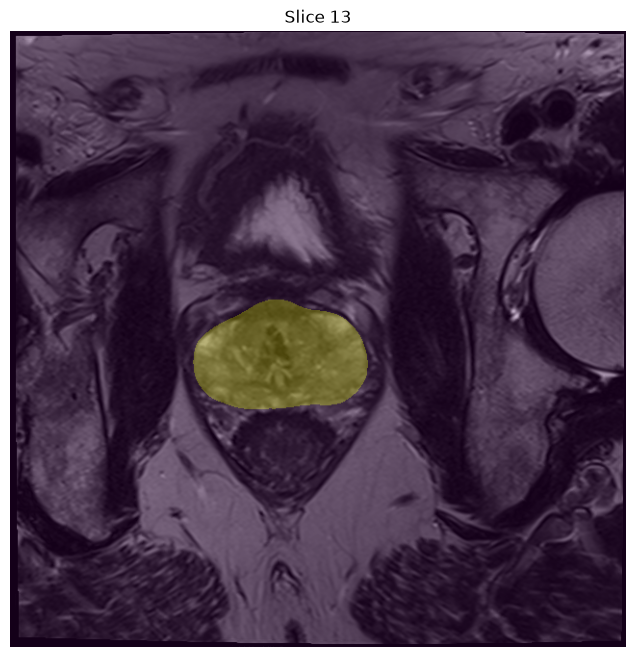

In [38]:
plot_slice_with_mask(
    t2w,
    mask,
    slice_index=13,
)

In [ ]:
compare_original_and_processed(
    image_slice,
    mask_slice,
    resized_image,
    resized_mask,
)

In [ ]:

saved_slices = process_case(
    patient_id="10000",
    study_id="1000000",
    output_dir=PROCESSED_DIR / "whole_gland_2d",
)

print("Saved slices:", saved_slices)

In [ ]:
cases = discover_t2w_cases()

print("Total cases:", len(cases))
print("First cases:", cases[:10])

In [ ]:
cases_with_mask = []
cases_without_mask = []

for patient_id, study_id in cases:
    mask_path = find_whole_gland_mask(
        patient_id,
        study_id,
    )

    if mask_path is not None:
        cases_with_mask.append((patient_id, study_id))
    else:
        cases_without_mask.append((patient_id, study_id))

print("Cases with mask:", len(cases_with_mask))
print("Cases without mask:", len(cases_without_mask))
print("First cases with mask:", cases_with_mask[:10])

In [ ]:
validation_results = []

for patient_id, study_id in cases[:10]:
    result = validate_case(
        patient_id,
        study_id,
    )

    validation_results.append(result)

    print(
        result["case_id"],
        "| valid:",
        result["valid"],
        "| image:",
        result["image_shape"],
        "| mask:",
        result["mask_shape"],
    )

In [ ]:
validation_results = []

for patient_id, study_id in cases:
    result = validate_case(
        patient_id,
        study_id,
    )

    validation_results.append(result)

valid_cases = [
    result
    for result in validation_results
    if result["valid"]
]

invalid_cases = [
    result
    for result in validation_results
    if not result["valid"]
]

print("Total cases:", len(validation_results))
print("Valid cases:", len(valid_cases))
print("Invalid cases:", len(invalid_cases))

In [ ]:
test_cases = cases[:50]

summary = process_dataset(
    cases=test_cases,
    output_dir=PROCESSED_DIR / "whole_gland_2d_test",
    context=2,
    image_size=(256, 256),
)

print("\nProcessing summary")
print("------------------")
print("Total cases:", summary["total_cases"])
print("Successful cases:", summary["successful_cases"])
print("Failed cases:", len(summary["failed_cases"]))
print("Total slices:", summary["total_slices"])

In [ ]:
summary = process_dataset(
    cases=cases,
    output_dir=PROCESSED_DIR / "whole_gland_2d",
    context=2,
    image_size=(256, 256),
)

print("\nProcessing summary")
print("------------------")
print("Total cases:", summary["total_cases"])
print("Successful cases:", summary["successful_cases"])
print("Failed cases:", len(summary["failed_cases"]))
print("Total slices:", summary["total_slices"])

In [10]:
clinical_data = pd.read_csv(clinical_path)

print("Total records:", len(clinical_data))

print(
    clinical_data["case_csPCa"]
    .value_counts(dropna=False)
)

print(
    clinical_data[
        [
            "patient_id",
            "study_id",
            "case_csPCa",
        ]
    ].head()
)

Total records: 1500
case_csPCa
NO     1075
YES     425
Name: count, dtype: int64
   patient_id  study_id case_csPCa
0       10000   1000000         NO
1       10001   1000001         NO
2       10002   1000002         NO
3       10003   1000003         NO
4       10004   1000004         NO


In [11]:
split_data = create_patient_splits(
    clinical_data,
    random_state=42,
)

print(
    split_data["split"].value_counts()
)

print()

print(
    pd.crosstab(
        split_data["split"],
        split_data["case_csPCa"],
        margins=True,
    )
)

split
train         1050
validation     225
test           225
Name: count, dtype: int64

case_csPCa    NO  YES   All
split                      
test         162   63   225
train        752  298  1050
validation   161   64   225
All         1075  425  1500


In [12]:
SPLITS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

split_path = SPLITS_DIR / "patient_splits.csv"

split_data.to_csv(
    split_path,
    index=False,
)

print("Split saved to:", split_path)

Split saved to: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\splits\patient_splits.csv


In [20]:
train_dataset = ProstateSegmentationDataset(
    images_dir=images_dir,
    masks_dir=masks_dir,
    splits_csv=splits_csv,
    split="train",
)

validation_dataset = ProstateSegmentationDataset(
    images_dir=images_dir,
    masks_dir=masks_dir,
    splits_csv=splits_csv,
    split="validation",
)

test_dataset = ProstateSegmentationDataset(
    images_dir=images_dir,
    masks_dir=masks_dir,
    splits_csv=splits_csv,
    split="test",
)

In [17]:
print("Train slices:", len(train_dataset))
print("Validation slices:", len(validation_dataset))
print("Test slices:", len(test_dataset))

print(
    "Total slices:",
    len(train_dataset)
    + len(validation_dataset)
    + len(test_dataset)
)

Train slices: 19551
Validation slices: 4246
Test slices: 4313
Total slices: 28110


In [21]:
image_tensor, mask_tensor = train_dataset[0]

print("Image shape:", image_tensor.shape)
print("Mask shape:", mask_tensor.shape)

print("Image dtype:", image_tensor.dtype)
print("Mask dtype:", mask_tensor.dtype)

print("Image min:", image_tensor.min().item())
print("Image max:", image_tensor.max().item())

print(
    "Mask values:",
    mask_tensor.unique().tolist(),
)

Image shape: torch.Size([1, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.float32
Image min: -1.443466305732727
Image max: 3.7537999153137207
Mask values: [0.0]


In [20]:
for index in range(len(train_dataset)):
    image_tensor, mask_tensor = train_dataset[index]

    if mask_tensor.max().item() > 0:
        print("First positive slice index:", index)
        print("Mask values:", mask_tensor.unique().tolist())
        print("Positive pixels:", int(mask_tensor.sum().item()))
        break

First positive slice index: 2
Mask values: [0.0, 1.0]
Positive pixels: 854


In [22]:

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
)

In [23]:
images, masks = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Mask values:", masks.unique().tolist())

Batch image shape: torch.Size([8, 1, 256, 256])
Batch mask shape: torch.Size([8, 1, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: [0.0, 1.0]


In [24]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = UNet(
    in_channels=1,
    out_channels=1,
).to(device)

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Device:", device)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Device: cuda
Input shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 1, 256, 256])


In [25]:
criterion = BCEDiceLoss()

masks = masks.to(device)

loss = criterion(
    outputs,
    masks,
)

print("Loss:", loss.item())

Loss: 0.7449905276298523


In [26]:
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4,
)

In [27]:
train_loss = train_one_epoch(
    model=model,
    dataloader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
)

print("Training loss:", train_loss)

KeyboardInterrupt: 

In [31]:
validation_loss = validate_one_epoch(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print("Validation loss:", validation_loss)

Validation loss: 0.17800690747250272


In [28]:
from src.data.paths import CHECKPOINTS_DIR
from src.segmentation.train import train_model


checkpoint_path = (
    CHECKPOINTS_DIR
    / "unet_whole_gland_best.pth"
)

history = train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=5,
    checkpoint_path=checkpoint_path,
)

KeyboardInterrupt: 

In [29]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    "Best epoch:",
    checkpoint["epoch"],
)

print(
    "Best validation loss:",
    checkpoint["validation_loss"],
)

Best epoch: 2
Best validation loss: 0.10171940835392744


In [30]:
validation_metrics = evaluate_model(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print(
    "Validation loss:",
    validation_metrics["loss"],
)

print(
    "Validation Dice:",
    validation_metrics["dice"],
)

KeyboardInterrupt: 

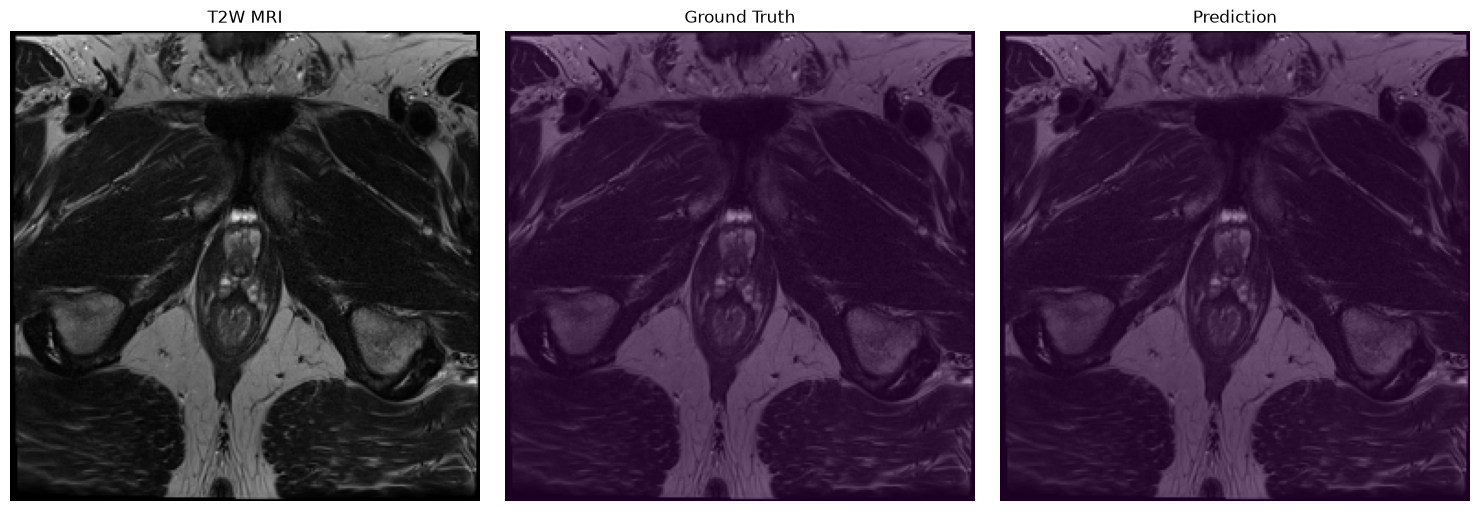

In [67]:
model.eval()

images, masks = next(
    iter(validation_loader)
)

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)


sample_index = 0

plot_segmentation_prediction(
    image=images[sample_index],
    mask=masks[sample_index],
    logits=outputs[sample_index],
)

In [31]:
positive_indices = []

for index in range(masks.size(0)):
    if masks[index].sum() > 0:
        positive_indices.append(index)

print(
    "Positive samples in batch:",
    positive_indices,
)

Positive samples in batch: [0, 1, 2, 3, 4, 5, 6, 7]


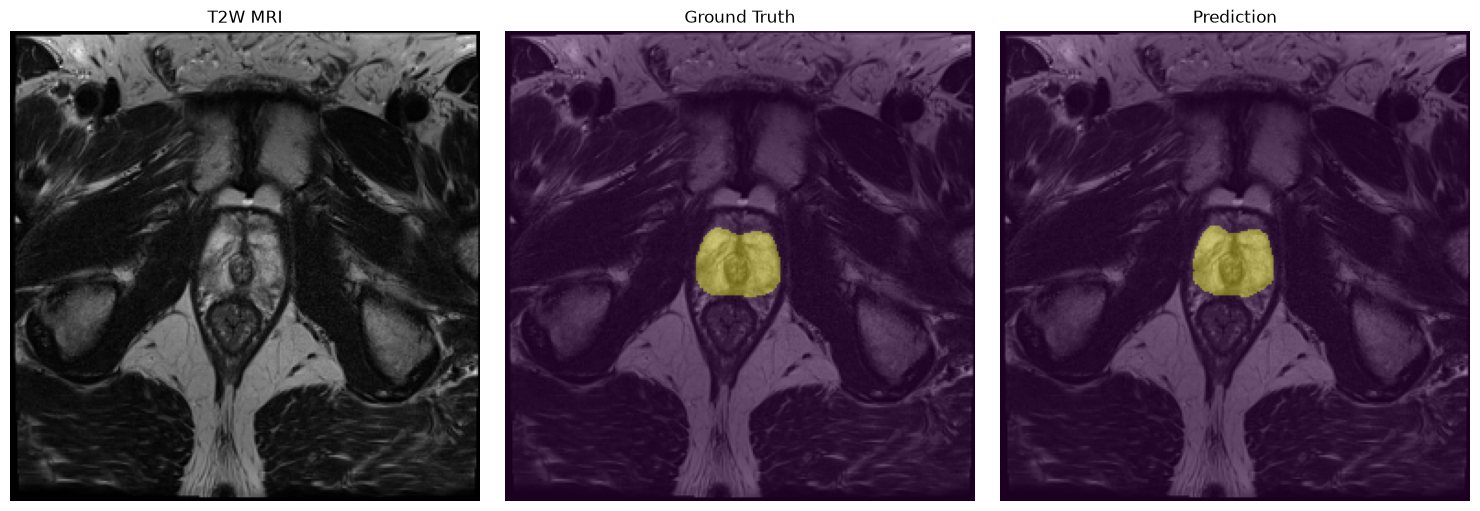

In [69]:
sample_index = 4

plot_segmentation_prediction(
    image=images[sample_index],
    mask=masks[sample_index],
    logits=outputs[sample_index],
)

In [82]:
validation_metrics = evaluate_model(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print(
    "Validation loss:",
    validation_metrics["loss"],
)

print(
    "Overall Dice:",
    validation_metrics["dice"],
)

print(
    "Positive-slice Dice:",
    validation_metrics["positive_dice"],
)

Validation loss: 0.10171940835392744
Overall Dice: 0.8324398500546673
Positive-slice Dice: 0.8330057431192276


In [8]:
validation_metrics = evaluate_model(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print(
    "Validation loss:",
    validation_metrics["loss"],
)

print(
    "Overall Dice:",
    validation_metrics["dice"],
)

print(
    "Positive-slice Dice:",
    validation_metrics["positive_dice"],
)

print(
    "IoU:",
    validation_metrics["iou"],
)

NameError: name 'model' is not defined

In [32]:
validation_metrics = evaluate_model(
    model=model,
    dataloader=validation_loader,
    criterion=criterion,
    device=device,
)

print(
    "Validation loss:",
    validation_metrics["loss"],
)

print(
    "Overall Dice:",
    validation_metrics["dice"],
)

print(
    "Positive-slice Dice:",
    validation_metrics["positive_dice"],
)

print(
    "IoU:",
    validation_metrics["iou"],
)

Validation loss: 0.10171940835392744
Overall Dice: 0.8324398500546673
Positive-slice Dice: 0.8330057431192276
IoU: 0.7851048020993249


In [33]:
test_metrics = evaluate_model(
    model=model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
)

print(
    "Test loss:",
    test_metrics["loss"],
)

print(
    "Test Dice:",
    test_metrics["dice"],
)

print(
    "Test positive-slice Dice:",
    test_metrics["positive_dice"],
)

print(
    "Test IoU:",
    test_metrics["iou"],
)

Test loss: 0.10233232652837479
Test Dice: 0.8344332212651218
Test positive-slice Dice: 0.8337442289983696
Test IoU: 0.7847313494042114


Save Metrics Data


In [35]:
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_data = {
    "dataset": [
        "validation",
        "test",
    ],
    "loss": [
        validation_metrics["loss"],
        test_metrics["loss"],
    ],
    "dice": [
        validation_metrics["dice"],
        test_metrics["dice"],
    ],
    "positive_slice_dice": [
        validation_metrics["positive_dice"],
        test_metrics["positive_dice"],
    ],
    "iou": [
        validation_metrics["iou"],
        test_metrics["iou"],
    ],
}

metrics_df = pd.DataFrame(
    metrics_data
)

output_path = (
    results_dir
    / "segmentation_metrics.csv"
)

metrics_df.to_csv(
    output_path,
    index=False,
)

print(metrics_df)
print()
print(
    "Saved to:",
    output_path,
)

      dataset      loss      dice  positive_slice_dice       iou
0  validation  0.101719  0.832440             0.833006  0.785105
1        test  0.102332  0.834433             0.833744  0.784731

Saved to: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\segmentation_metrics.csv
